<a href="https://colab.research.google.com/github/Separd-sudo/evaluacion1-deep-learning-mlp/blob/develop/Evaluacion_MLP_Dataset_BankMarketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación — Red Neuronal Multicapa (MLP) para clasificación
## Dataset: *Bank Marketing* (UCI Machine Learning Repository)

### Contexto del problema

Un banco portugués realizó **campañas de marketing telefónico** para ofrecer a sus clientes un **depósito a plazo**. Por cada cliente contactado se registraron sus datos personales, su situación financiera y el historial de contactos de la campaña.

**Objetivo:** construir un modelo que prediga si un cliente **contratará el depósito a plazo** (`y = "yes"`) o **no** (`y = "no"`).

| | |
|---|---|
| **Tipo de problema** | Clasificación **binaria** |
| **Registros** | 45.211 clientes |
| **Variables de entrada** | 16 (7 numéricas y 9 categóricas) |
| **Variable objetivo** | `y` ("yes" / "no") |
| **Fuente** | [UCI Machine Learning Repository — Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) |
| **Licencia** | CC BY 4.0 |
| **Cita** | Moro, S., Cortez, P. & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing.* Decision Support Systems, 62, 22–31. |

## ¿Qué deben demostrar?

1. Cargar y **preprocesar** correctamente los datos.
2. **Diseñar e implementar** una arquitectura MLP (TensorFlow/Keras o PyTorch).
3. Configurar **parámetros de entrenamiento**: épocas, tasa de aprendizaje y tamaño de batch.
4. **Comparar** distintas funciones de **activación** y funciones de **pérdida**.
5. Aplicar técnicas de **optimización** y **regularización**.
6. **Evaluar** el desempeño con **Accuracy, Precision, Recall y F1-Score**.
7. **Analizar** los resultados y **justificar** las mejoras realizadas al modelo.

> Este notebook **solo carga y describe los datos**. Todo el preprocesamiento, el modelo y el análisis son parte de su trabajo.

## 1. Cargar los datos

Ejecuta **una** de las dos opciones.

**Opción A (recomendada): descarga directa desde UCI.** Funciona en Google Colab y en Jupyter local. Solo requiere internet.

In [7]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt

URL_UCI = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(URL_UCI) as resp:
    zip_externo = zipfile.ZipFile(io.BytesIO(resp.read()))
zip_interno = zipfile.ZipFile(io.BytesIO(zip_externo.read("bank.zip")))   # el archivo viene comprimido dos veces
df = pd.read_csv(zip_interno.open("bank-full.csv"), sep=";")

print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

Datos cargados: 45211 filas x 17 columnas


**Opción B: desde el archivo `bank_marketing.csv` entregado por el docente.**

- **En Colab:** sube el archivo con el ícono de carpeta (panel izquierdo → *Subir*) y ejecuta la celda.
- **En Jupyter local:** deja el CSV en la misma carpeta que este notebook.
- **Desde un enlace** (Google Drive / GitHub): pega el enlace en `ENLACE`. Si es de Google Drive, el archivo debe estar compartido como *"Cualquier persona con el enlace"*.

In [9]:
ENLACE = ""   # opcional: pega aquí el enlace entregado por el docente

def enlace_descarga(url):
    # Convierte un enlace "compartir" de Google Drive en un enlace de descarga directa
    if "drive.google.com" in url and "/d/" in url:
        file_id = url.split("/d/")[1].split("/")[0]
        return f"https://drive.google.com/uc?export=download&id={file_id}"
    return url

df = pd.read_csv(enlace_descarga(ENLACE) if ENLACE else "bank_marketing.csv")
print("Datos cargados:", df.shape[0], "filas x", df.shape[1], "columnas")

FileNotFoundError: [Errno 2] No such file or directory: 'bank_marketing.csv'

## 2. Diccionario de variables

**Datos del cliente**

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | numérica | Edad |
| `job` | categórica | Tipo de trabajo (`admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`) |
| `marital` | categórica | Estado civil (`married`, `single`, `divorced` — "divorced" incluye viudos) |
| `education` | categórica | Nivel educacional (`primary`, `secondary`, `tertiary`, `unknown`) |
| `default` | binaria | ¿Tiene créditos en mora? (`yes` / `no`) |
| `balance` | numérica | Saldo promedio anual, en euros (puede ser negativo) |
| `housing` | binaria | ¿Tiene crédito hipotecario? |
| `loan` | binaria | ¿Tiene crédito de consumo? |

**Último contacto de la campaña actual**

| Variable | Tipo | Descripción |
|---|---|---|
| `contact` | categórica | Medio de contacto (`cellular`, `telephone`, `unknown`) |
| `day` | numérica | Día del mes del último contacto |
| `month` | categórica | Mes del último contacto (`jan` … `dec`) |
| `duration` | numérica | Duración del último contacto, en segundos ⚠️ *(ver nota importante más abajo)* |

**Otros atributos**

| Variable | Tipo | Descripción |
|---|---|---|
| `campaign` | numérica | N° de contactos realizados a este cliente en esta campaña (incluye el último) |
| `pdays` | numérica | Días transcurridos desde el último contacto de una campaña **anterior** (`-1` = nunca fue contactado antes) |
| `previous` | numérica | N° de contactos realizados antes de esta campaña |
| `poutcome` | categórica | Resultado de la campaña anterior (`success`, `failure`, `other`, `unknown`) |

**Variable objetivo**

| Variable | Tipo | Descripción |
|---|---|---|
| `y` | binaria | ¿El cliente contrató el depósito a plazo? (`yes` / `no`) |

## 3. Primera mirada a los datos

In [10]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.describe().round(2)

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


### Distribución de la variable objetivo

,cantidad,porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


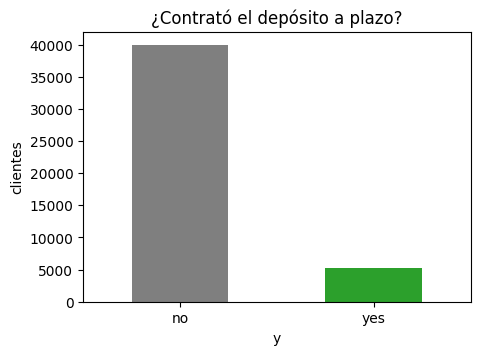

In [11]:
conteo = df["y"].value_counts()
porcentaje = df["y"].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({"cantidad": conteo, "porcentaje (%)": porcentaje}))

conteo.plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 3.5), rot=0,
            title="¿Contrató el depósito a plazo?")
plt.ylabel("clientes")
plt.show()

### Valores "unknown"

El dataset **no tiene celdas vacías**, pero varias columnas categóricas usan el texto `"unknown"` cuando no se conoce el dato.

In [12]:
print("Celdas vacías (NaN):", df.isna().sum().sum())
categoricas = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
unknown = {c: int((df[c] == "unknown").sum()) for c in categoricas}
pd.Series(unknown, name="cantidad de 'unknown'").to_frame().query("`cantidad de 'unknown'` > 0")

Celdas vacías (NaN): 0


,cantidad de 'unknown'
job,288
education,1857
contact,13020
poutcome,36959


## 4. Consideraciones importantes

1. **Clases desbalanceadas.** Solo ~12 % de los clientes contrató el depósito. Un modelo que responda siempre `"no"` obtiene **~88 % de Accuracy** sin haber aprendido nada. Por eso **Precision, Recall y F1-Score** de la clase `"yes"` son fundamentales para evaluar los modelos.
2. **La variable `duration`.** La duración de la llamada solo se conoce **después** de hacerla, y cuando `duration = 0` el resultado siempre es `"no"`. Los autores del dataset recomiendan **no usarla** si el objetivo es un modelo predictivo realista (uno que se use *antes* de llamar al cliente). Decidan si la incluyen o no y **justifiquen** su decisión en el análisis.
3. **Variables categóricas.** La red neuronal necesita números: hay que transformar las variables de texto.
4. **Escalas muy distintas.** Por ejemplo, `balance` va de miles de euros negativos a más de 100.000, mientras que `previous` suele estar entre 0 y 5.
5. **`pdays = -1`** no es un número de días: significa "nunca contactado antes".
6. **Separación de datos.** Todo lo que el preprocesamiento "aprende" (medias, escalas, categorías) debe calcularse **solo con los datos de entrenamiento**.

## 5. Su trabajo comienza aquí ⬇️

Sugerencia de estructura para el notebook de entrega:

1. Análisis exploratorio y preprocesamiento
2. Separación en entrenamiento / validación / prueba
3. Modelo base (MLP) y configuración de entrenamiento
4. Comparación de funciones de activación y de pérdida
5. Optimización y regularización
6. Evaluación final: Accuracy, Precision, Recall, F1-Score y matriz de confusión
7. Análisis de resultados y justificación de las mejoras

## 5.1 Fase 1 y 2: Preprocesamiento de Datos y División (Train / Validation / Test)

Para que la Red Neuronal Multicapa (MLP) converja adecuadamente y tenga capacidad de generalización, aplicamos las siguientes decisiones técnicas justificadas en las características del dataset *Bank Marketing*:

1. **Eliminación de la variable `duration` (Prevención de *Data Leakage*):**
   La duración de la llamada solo se conoce una vez finalizado el contacto telefónico (y si `duration = 0`, la variable objetivo es invariablemente `"no"`). Incluirla generaría fuga de información del futuro (*data leakage*), impidiendo usar el modelo de forma predictiva antes de contactar al cliente. Siguiendo la recomendación de los autores (Moro et al., 2014), se excluye del entrenamiento.
2. **Tratamiento especial de `pdays = -1`:**
   El valor `-1` indica que el cliente nunca fue contactado previamente (~81.7% de los casos). Para evitar que la red interprete `-1` como una magnitud numérica continua negativa, se crea la variable binaria `contactado_antes` (`1` si `pdays != -1`, `0` si `pdays == -1`) y se reemplaza el `-1` por `0`.
3. **Codificación de variables categóricas y binarias:**
   Las redes neuronales operan exclusivamente con tensores numéricos. Las variables binarias (`default`, `housing`, `loan` y el target `y`) se mapean a `0` y `1`. Las variables categóricas nominales (`job`, `marital`, `education`, `contact`, `month`, `poutcome`, incluyendo la categoría `"unknown"` como información explícita) se transforman mediante **One-Hot Encoding** (`drop_first=True` para evitar multicolinealidad), pasando a 42 variables predictoras.
4. **División Estratificada (70% Entrenamiento / 15% Validación / 15% Prueba):**
   Dado el fuerte desbalance de clases (88.3% `"no"` vs 11.7% `"yes"`), se utiliza muestreo estratificado (`stratify=y`) para conservar exactamente el 11.7% de casos positivos en los tres subconjuntos.
5. **Escalado Estandarizado (`StandardScaler`) sin Fuga de Datos:**
   Variables como `balance` (rango de miles de euros) y `previous` (unidades) tienen escalas muy dispares, lo que distorsiona los gradientes en el descenso del gradiente. Se aplica `StandardScaler` ($\mu=0, \sigma=1$) ajustando los parámetros (`fit`) **únicamente sobre el conjunto de entrenamiento** y transformando validación y prueba.
6. **Pesos de Clase (`class_weight`):**
   Para evitar que el modelo converja a la clase mayoritaria (`"no"`), se calculan pesos inversamente proporcionales a la frecuencia de cada clase en el conjunto de entrenamiento.

In [13]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# 1. Eliminamos 'duration' para evitar fuga de datos (data leakage)
df_proc = df.drop(columns=["duration"]).copy()

# 2. Tratamiento de 'pdays = -1'
df_proc["contactado_antes"] = (df_proc["pdays"] != -1).astype(int)
df_proc["pdays"] = df_proc["pdays"].replace(-1, 0)

# 3. Codificación de variables binarias (0 y 1)
cols_binarias = ["default", "housing", "loan", "y"]
for col in cols_binarias:
    df_proc[col] = df_proc[col].map({"yes": 1, "no": 0})

# 4. One-Hot Encoding para variables categóricas
cols_categoricas = ["job", "marital", "education", "contact", "month", "poutcome"]
df_encoded = pd.get_dummies(df_proc, columns=cols_categoricas, drop_first=True, dtype=int)

print(f"Dimensiones tras codificación: {df_encoded.shape[0]} filas x {df_encoded.shape[1]} columnas")

# 5. Separación Estratificada: 70% Train, 15% Validation, 15% Test
X = df_encoded.drop(columns=["y"])
y = df_encoded["y"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# 6. Escalado de variables numéricas (fit SOLO en X_train)
cols_numericas = ["age", "balance", "day", "campaign", "pdays", "previous"]
scaler = StandardScaler()

X_train[cols_numericas] = scaler.fit_transform(X_train[cols_numericas])
X_val[cols_numericas] = scaler.transform(X_val[cols_numericas])
X_test[cols_numericas] = scaler.transform(X_test[cols_numericas])

# 7. Cálculo de pesos de clase para compensar el desbalance (88.3% vs 11.7%)
pesos = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=y_train)
class_weights = {0: pesos[0], 1: pesos[1]}

# Resumen de verificación
resumen_split = pd.DataFrame({
    "Conjunto": ["Entrenamiento (70%)", "Validación (15%)", "Prueba (15%)"],
    "Filas": [X_train.shape[0], X_val.shape[0], X_test.shape[0]],
    "Features (X)": [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    "Proporción 'yes' (%)": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})
display(resumen_split)
print(f"Pesos de clase calculados: Clase 0 ('no') = {class_weights[0]:.3f} | Clase 1 ('yes') = {class_weights[1]:.3f}")

Dimensiones tras codificación: 45211 filas x 43 columnas


,Conjunto,Filas,Features (X),Proporción 'yes' (%)
0,Entrenamiento (70%),31647,42,11.70
1,Validación (15%),6782,42,11.71
2,Prueba (15%),6782,42,11.69


Pesos de clase calculados: Clase 0 ('no') = 0.566 | Clase 1 ('yes') = 4.274


## 5.2 Fase 3: Arquitectura y Entrenamiento del Modelo Base (MLP)

Diseñamos un Perceptrón Multicapa (MLP) secuencial en TensorFlow/Keras con una estructura piramidal decreciente para comprimir progresivamente las 42 variables de entrada hacia la decisión binaria:

* **Capa de Entrada (`Input`):** 42 neuronas (correspondientes a las 42 características preprocesadas).
* **Capa Oculta 1 (`Dense`):** 64 neuronas con función de activación **ReLU** ($\max(0, x)$), que introduce no-linealidad evitando el desvanecimiento del gradiente.
* **Capa Oculta 2 (`Dense`):** 32 neuronas con activación **ReLU**, refinando las representaciones abstractas aprendidas en la primera capa.
* **Capa de Salida (`Dense`):** 1 neurona con activación **Sigmoide** ($\sigma(z) = \frac{1}{1 + e^{-z}}$), que acota la salida al rango $[0, 1]$ para interpretarla como la probabilidad de que el cliente contrate el depósito (`y = 1`).

**Configuración de Entrenamiento Inicial:**
* **Función de pérdida:** `binary_crossentropy` (entropía cruzada binaria), estándar matemático para medir la divergencia entre probabilidades predichas y etiquetas binarias reales.
* **Optimizador y Tasa de Aprendizaje:** `Adam` con `learning_rate = 0.001` (combina momento e historial adaptativo de gradientes).
* **Tamaño de Batch (`batch_size`):** `64` muestras por actualización de pesos (equilibrio entre estabilidad del gradiente y velocidad).
* **Épocas (`epochs`):** `25` iteraciones completas sobre el conjunto de entrenamiento, aplicando `class_weight` para penalizar errores en la clase minoritaria.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 64)             │         2,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,865 (19.00 KB)

 Trainable params: 4,865 (19.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7244 - loss: 0.5937 - val_accuracy: 0.7678 - val_loss: 0.5454
Epoch 2/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7702 - loss: 0.5544 - val_accuracy: 0.7738 - val_loss: 0.5431
Epoch 3/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7780 - loss: 0.5447 - val_accuracy: 0.7738 - val_loss: 0.5412
Epoch 4/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7826 - loss: 0.5381 - val_accuracy: 0.7700 - val_loss: 0.5411
Epoch 5/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7842 - loss: 0.5332 - val_accuracy: 0.7720 - val_loss: 0.5365
Epoch 6/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7875 - loss: 0.5289 - val_accuracy: 0.7782 - val_loss: 0.5288
Epoch 7/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7902 - loss: 0.5248 - val_accuracy: 0.7802 - val_loss: 0.5258
Epoch 8/25
495/495 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7928 - loss: 0.5211 - val_accuracy: 0.

,Métrica,Valor Validación
0,Accuracy,0.7744
1,Precision (Clase 'yes'),0.2848
2,Recall (Clase 'yes'),0.6134
3,F1-Score (Clase 'yes'),0.3890


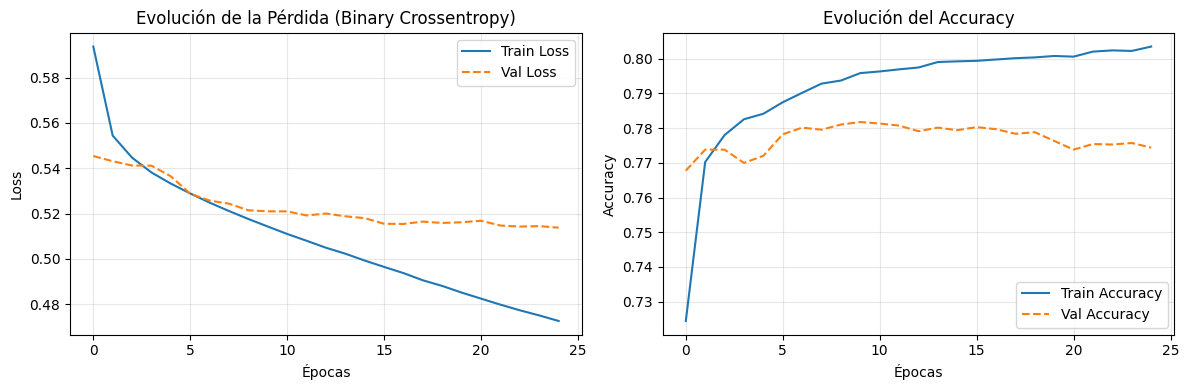

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

# Fijamos semillas para reproducibilidad de los experimentos
tf.random.set_seed(42)
np.random.seed(42)

def crear_modelo_base(input_dim, lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu", name="capa_oculta_1"),
        layers.Dense(32, activation="relu", name="capa_oculta_2"),
        layers.Dense(1, activation="sigmoid", name="capa_salida")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Instanciar y mostrar arquitectura
modelo_base = crear_modelo_base(X_train.shape[1], lr=0.001)
modelo_base.summary()

# Entrenamiento del modelo base
history_base = modelo_base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=64,
    class_weight=class_weights,
    verbose=1
)

# Evaluación en conjunto de Validación
y_val_prob = modelo_base.predict(X_val, verbose=0)
y_val_pred = (y_val_prob >= 0.5).astype(int)

metricas_base = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision (Clase 'yes')", "Recall (Clase 'yes')", "F1-Score (Clase 'yes')"],
    "Valor Validación": [
        round(accuracy_score(y_val, y_val_pred), 4),
        round(precision_score(y_val, y_val_pred), 4),
        round(recall_score(y_val, y_val_pred), 4),
        round(f1_score(y_val, y_val_pred), 4)
    ]
})
display(metricas_base)

# Gráfico de curvas de aprendizaje (Loss y Accuracy)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_base.history["loss"], label="Train Loss")
axes[0].plot(history_base.history["val_loss"], label="Val Loss", linestyle="--")
axes[0].set_title("Evolución de la Pérdida (Binary Crossentropy)")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_base.history["accuracy"], label="Train Accuracy")
axes[1].plot(history_base.history["val_accuracy"], label="Val Accuracy", linestyle="--")
axes[1].set_title("Evolución del Accuracy")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.3 Fase 4: Experimentos Controlados de Hiperparámetros (Uno a la vez)

Para evaluar el impacto real de cada hiperparámetro sobre la convergencia del modelo, realizamos experimentos controlados (*ceteris paribus*), variando **un único parámetro a la vez** y manteniendo fijos los demás:

1. **Experimento 1 — Tasa de Aprendizaje (`learning_rate`):** Evaluamos `[0.01, 0.001, 0.0001]` dejando fijo `batch_size = 128` y `epochs = 12`.
   * *Hipótesis técnica:* Un LR muy alto (`0.01`) dará pasos demasiado grandes causando inestabilidad en la pérdida; uno muy bajo (`0.0001`) convergerá lento; `0.001` logrará el mejor equilibrio.
2. **Experimento 2 — Tamaño de Lote (`batch_size`):** Evaluamos `[64, 128, 256]` dejando fijo `learning_rate = 0.001` y `epochs = 12`.
   * *Hipótesis técnica:* Batches pequeños (`64`) introducen más ruido estocástico (mayor *Recall* pero menor precisión), mientras que batches más grandes (`256`) estabilizan el gradiente mejorando el *F1-Score* y la velocidad de cómputo.
3. **Experimento 3 — Número de Épocas (`epochs`):** Evaluamos
5, 12 y 25 épocas, manteniendo fijos `learning_rate = 0.001`
y `batch_size = 256`. Comparamos las métricas obtenidas y la
pérdida final de validación para observar el efecto de la duración
del entrenamiento. Las curvas de pérdida de entrenamiento y
validación para analizar el sobreajuste se estudian en la sección 5.5.

=== TABLA 3: IMPACTO DEL NÚMERO DE ÉPOCAS ===


,Accuracy,Precision,Recall,F1-Score,Val Loss Final
"Epochs = 5 (LR=0.001, Batch=256)",0.8195,0.3455,0.6058,0.4401,0.4824
"Epochs = 12 (LR=0.001, Batch=256)",0.8114,0.3363,0.6272,0.4378,0.4766
"Epochs = 25 (LR=0.001, Batch=256)",0.8179,0.3461,0.6247,0.4454,0.4785


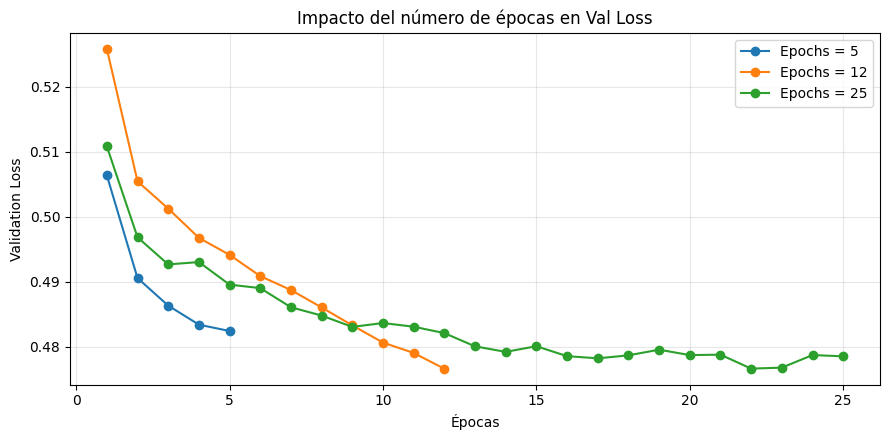

In [15]:
# 3. Experimento variando el número de épocas
# Parámetros fijos: learning_rate = 0.001 y batch_size = 256

epocas_prueba = [5, 12, 25]

curvas_epocas = {}
tabla_epocas = {}

for n_epocas in epocas_prueba:

    # Reutilizamos la función auxiliar existente del notebook
    curva, met = experimento_controlado(
        lr=0.001,
        batch_size=256,
        epochs=n_epocas
    )

    curvas_epocas[f"Epochs = {n_epocas}"] = curva

    tabla_epocas[
        f"Epochs = {n_epocas} (LR=0.001, Batch=256)"
    ] = met

# Tabla comparativa de resultados
print("=== TABLA 3: IMPACTO DEL NÚMERO DE ÉPOCAS ===")
display(pd.DataFrame(tabla_epocas).T)

# Gráfico comparativo de pérdida de validación
plt.figure(figsize=(9, 4.5))

for nombre, curva in curvas_epocas.items():
    plt.plot(
        range(1, len(curva) + 1),
        curva,
        marker="o",
        label=nombre
    )

plt.title("Impacto del número de épocas en Val Loss")
plt.xlabel("Épocas")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5.4 Fase 5: Comparación de Funciones de Activación y Pérdida

Mantenemos fijos los parámetros de entrenamiento durante esta comparación
(`learning_rate = 0.001`, `batch_size = 256` y `epochs = 12`), para evaluar
el efecto de las funciones de activación y pérdida.

En los experimentos anteriores, `learning_rate = 0.01` obtuvo el mayor
F1-Score (0.4238), mientras que `learning_rate = 0.001` obtuvo la menor
pérdida final de validación (0.5159). Se mantiene `0.001` para las
comparaciones siguientes por su resultado en la pérdida de validación,
sin afirmar que sea la mejor tasa para todas las métricas.

Por otra parte, `batch_size = 256` obtuvo el mayor F1-Score (0.4428)
y la menor pérdida final de validación (0.4745) entre los tamaños
de lote evaluados. Las funciones se comparan manteniendo constantes
los parámetros anteriores, para que los resultados sean interpretables.

### 1. Funciones de Activación en Capas Ocultas:
* **ReLU ($\max(0, z)$):** Estándar computacionalmente eficiente, pero puede sufrir de *"neuronas muertas"* (*dying ReLU*) cuando recibe entradas negativas persistentes (su derivada es $0$ para $z < 0$).
* **Tanh ($\tanh(z)$):** Acota las salidas a $[-1, 1]$ centrando los datos en cero, pero en los extremos sus derivadas se acercan a cero, provocando **desvanecimiento del gradiente** (*vanishing gradient*).
* **LeakyReLU ($\max(0.1z, z)$):** Permite una pequeña pendiente negativa ($\alpha = 0.1$) para $z < 0$, evitando que las neuronas mueran y conservando el flujo de gradientes en atributos estandarizados negativos.

### 2. Funciones de Pérdida (Error):
* **Binary Crossentropy (Entropía Cruzada Binaria):** Penaliza logarítmicamente las predicciones erróneas seguras; es la función teóricamente óptima para salidas sigmoides (estimación de máxima verosimilitud Bernoulli).
* **MSE (Error Cuadrático Medio):** Diseñada para problemas de regresión; al acoplarse con una capa Sigmoide produce gradientes pequeños cuando la neurona se satura, ralentizando el aprendizaje.
* **Binary Focal Crossentropy ($\gamma = 2.0$):** Reduce el peso de los ejemplos fáciles de clasificar para concentrar el gradiente en los casos difíciles de la clase minoritaria.

=== TABLA COMPARATIVA DE FUNCIONES DE ACTIVACIÓN Y PÉRDIDA ===


,Accuracy,Precision,Recall,F1-Score
ReLU + Binary Crossentropy,0.8228,0.3520,0.6108,0.4466
Tanh + Binary Crossentropy,0.8020,0.3202,0.6159,0.4214
LeakyReLU + Binary Crossentropy,0.8231,0.3518,0.6071,0.4455
ReLU + MSE (Error Cuadrático),0.8270,0.3599,0.6134,0.4537
ReLU + Binary Focal Loss,0.8127,0.3343,0.6045,0.4305


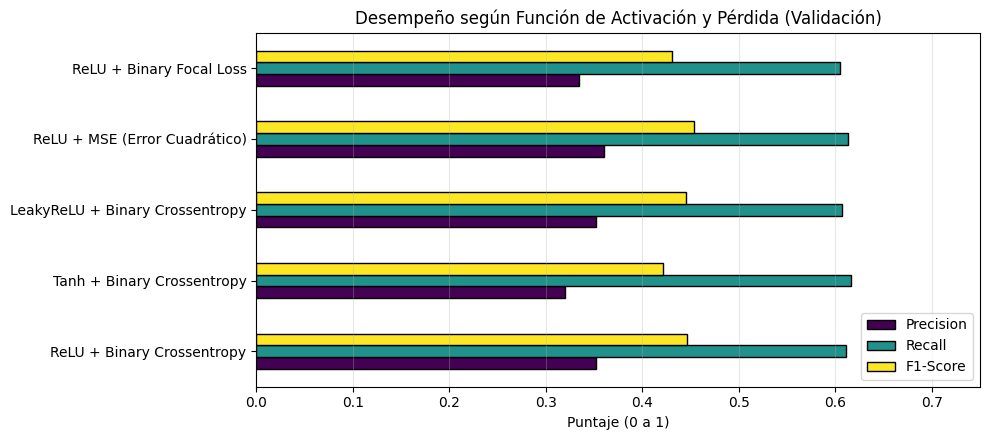

In [16]:
def entrenar_variante(activacion="relu", perdida="binary_crossentropy", usar_focal=False):
    tf.random.set_seed(42)
    np.random.seed(42)

    if activacion == "leaky_relu":
        act_fn = layers.LeakyReLU(negative_slope=0.1)
    else:
        act_fn = activacion

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation=act_fn),
        layers.Dense(32, activation=act_fn),
        layers.Dense(1, activation="sigmoid")
    ])

    loss_fn = keras.losses.BinaryFocalCrossentropy(gamma=2.0) if usar_focal else perdida

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=loss_fn,
        metrics=["accuracy"]
    )

    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=12,
        batch_size=256,
        class_weight=class_weights,
        verbose=0
    )
    preds = (model.predict(X_val, verbose=0) >= 0.5).astype(int)
    return hist.history["val_loss"], {
        "Accuracy": round(accuracy_score(y_val, preds), 4),
        "Precision": round(precision_score(y_val, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_val, preds, zero_division=0), 4),
        "F1-Score": round(f1_score(y_val, preds, zero_division=0), 4)
    }

configuraciones = [
    ("ReLU + Binary Crossentropy", "relu", "binary_crossentropy", False),
    ("Tanh + Binary Crossentropy", "tanh", "binary_crossentropy", False),
    ("LeakyReLU + Binary Crossentropy", "leaky_relu", "binary_crossentropy", False),
    ("ReLU + MSE (Error Cuadrático)", "relu", "mse", False),
    ("ReLU + Binary Focal Loss", "relu", "binary_crossentropy", True)
]

curvas_fn, tabla_fn = {}, {}
for nombre, act, loss, focal in configuraciones:
    curva, met = entrenar_variante(act, loss, focal)
    curvas_fn[nombre] = curva
    tabla_fn[nombre] = met

df_comparacion_fn = pd.DataFrame(tabla_fn).T
print("=== TABLA COMPARATIVA DE FUNCIONES DE ACTIVACIÓN Y PÉRDIDA ===")
display(df_comparacion_fn)

# Gráfico comparativo de métricas clave (F1-Score y Recall)
ax = df_comparacion_fn[["Precision", "Recall", "F1-Score"]].plot(
    kind="barh", figsize=(10, 4.5), colormap="viridis", edgecolor="black"
)
plt.title("Desempeño según Función de Activación y Pérdida (Validación)")
plt.xlabel("Puntaje (0 a 1)")
plt.xlim(0, 0.75)
plt.grid(axis="x", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 5.5 Fase 6: Optimización y Regularización del Modelo

En el modelo sin regularizar observamos que, al aumentar las épocas, la pérdida de entrenamiento (`train_loss`) disminuye continuamente mientras la pérdida de validación (`val_loss`) se separa y sube, evidenciando **sobreajuste (*overfitting*)**. Para estabilizar el aprendizaje y mejorar la generalización en clientes no vistos, incorporamos tres mecanismos complementarios:

1. **Batch Normalization (`BatchNormalization`):** Normaliza las activaciones intermedias de cada mini-lote ($\mu \approx 0, \sigma \approx 1$) antes de la función de activación. Esto reduce el cambio de covarianza interna (*internal covariate shift*) y suaviza la superficie de pérdida.
2. **Dropout (`0.3` en capa 1 y `0.2` en capa 2):** Apaga aleatoriamente el 30% y 20% de las neuronas en cada paso de entrenamiento, impidiendo la co-adaptación de neuronas (que la red memorice casos específicos) y actuando como un ensamble implícito de sub-redes.
3. **Regularización L2 (`kernel_regularizer = l2(1e-4)`):** Añade una penalización proporcional al cuadrado de los pesos ($\lambda \sum w_i^2$) en la función de costo, manteniendo los pesos pequeños y evitando fronteras de decisión excesivamente complejas.

=== IMPACTO DE LA REGULARIZACIÓN Y OPTIMIZACIÓN ===


,Accuracy,Precision,Recall,F1-Score,Brecha Overfitting |Val - Train Loss|
MLP Sin Regularización,0.8160,0.3383,0.5982,0.4322,0.0309
MLP Con BatchNorm + Dropout + L2,0.8014,0.3235,0.6385,0.4295,0.0259


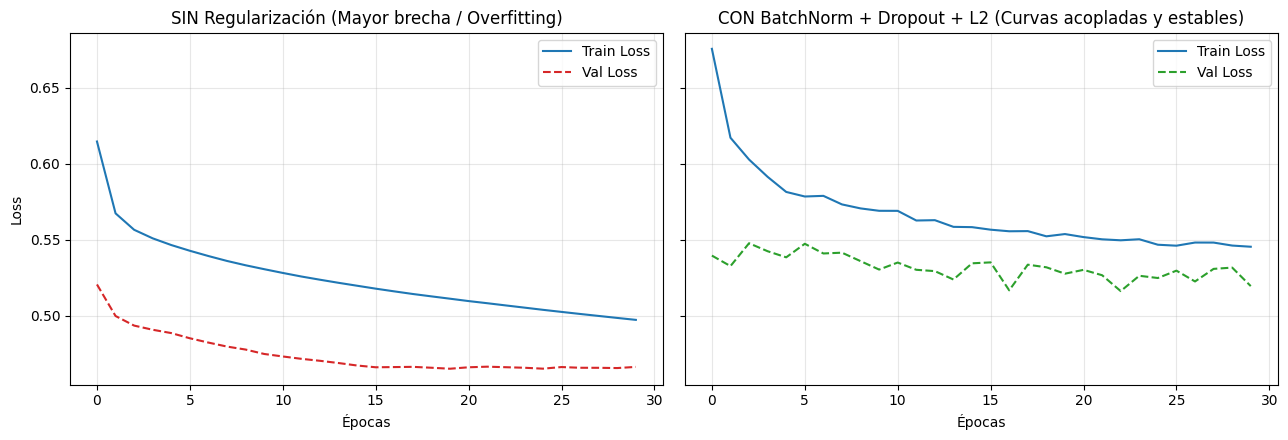

In [17]:
from tensorflow.keras import regularizers

# 1. Modelo SIN regularización (entrenado por 30 épocas para visualizar el sobreajuste)
tf.random.set_seed(42)
np.random.seed(42)

modelo_sin_reg = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation=layers.LeakyReLU(negative_slope=0.1)),
    layers.Dense(32, activation=layers.LeakyReLU(negative_slope=0.1)),
    layers.Dense(1, activation="sigmoid")
])
modelo_sin_reg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
hist_sin_reg = modelo_sin_reg.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    verbose=0
)

# 2. Modelo CON Regularización y Optimización (BatchNorm + Dropout + L2)
tf.random.set_seed(42)
np.random.seed(42)

modelo_optimizado = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dropout(0.3),

    layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])
modelo_optimizado.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
hist_con_reg = modelo_optimizado.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    verbose=0
)

# Comparación en tabla
res_reg = {}
for nombre, mod, hist in [
    ("MLP Sin Regularización", modelo_sin_reg, hist_sin_reg),
    ("MLP Con BatchNorm + Dropout + L2", modelo_optimizado, hist_con_reg)
]:
    preds = (mod.predict(X_val, verbose=0) >= 0.5).astype(int)
    gap_overfitting = abs(hist.history["val_loss"][-1] - hist.history["loss"][-1])
    res_reg[nombre] = {
        "Accuracy": round(accuracy_score(y_val, preds), 4),
        "Precision": round(precision_score(y_val, preds), 4),
        "Recall": round(recall_score(y_val, preds), 4),
        "F1-Score": round(f1_score(y_val, preds), 4),
        "Brecha Overfitting |Val - Train Loss|": round(gap_overfitting, 4)
    }

print("=== IMPACTO DE LA REGULARIZACIÓN Y OPTIMIZACIÓN ===")
display(pd.DataFrame(res_reg).T)

# Gráficos comparativos de estabilidad (Con vs Sin Optimización)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].plot(hist_sin_reg.history["loss"], label="Train Loss", color="tab:blue")
axes[0].plot(hist_sin_reg.history["val_loss"], label="Val Loss", color="tab:red", linestyle="--")
axes[0].set_title("SIN Regularización (Mayor brecha / Overfitting)")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hist_con_reg.history["loss"], label="Train Loss", color="tab:blue")
axes[1].plot(hist_con_reg.history["val_loss"], label="Val Loss", color="tab:green", linestyle="--")
axes[1].set_title("CON BatchNorm + Dropout + L2 (Curvas acopladas y estables)")
axes[1].set_xlabel("Épocas")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5.6 Fase 7: Evaluación Final en Conjunto de Prueba (Test) y Mejora de Precision/Recall

Para evaluar rigurosamente la solución frente a datos nunca vistos (`X_test`, 6.782 clientes), definimos e interpretamos las 4 métricas fundamentales en el contexto bancario (donde Positivo `1` = contrata el depósito, Negativo `0` = no contrata):

* **Accuracy ($\frac{VP + VN}{Total}$):** Porcentaje total de aciertos. *Limitación:* En este dataset desbalanceado (88.3% `"no"`), no refleja el éxito comercial por sí solo.
* **Precision ($\frac{VP}{VP + FP}$):** De todos los clientes que el modelo recomienda llamar, ¿qué porcentaje realmente contrata el depósito? Mejorar la *Precision* **reduce llamadas perdidas y costos de call center** (menos Falsos Positivos).
* **Recall o Sensibilidad ($\frac{VP}{VP + FN}$):** De todos los clientes que sí habrían contratado el depósito, ¿qué porcentaje logró captar el modelo? Mejorar el *Recall* **evita perder ventas potenciales** (menos Falsos Negativos).
* **F1-Score ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$):** Media armónica que equilibra *Precision* y *Recall* en una sola métrica robusta frente al desbalance.

### Estrategia para mejorar Precision y F1-Score: Optimización del Umbral de Decisión
Al entrenar con `class_weight` balanceado, el umbral por defecto (0.50)
obtuvo en test una Precision de 0.3047, un Recall de 0.6343 y un
F1-Score de 0.4116 para el modelo optimizado.

El umbral se selecciona mediante una búsqueda sobre el conjunto de
validación. En la ejecución registrada, el valor seleccionado fue
`0.66`, no `0.72`. Al aplicar este umbral al conjunto de prueba,
la Precision aumentó a 0.4537 y el F1-Score a 0.4731, mientras que
el Recall disminuyó a 0.4943 y el Accuracy fue 0.8713 (87.13%).

Este ajuste mejora el equilibrio entre Precision y Recall según el
F1-Score, pero no mejora el Accuracy respecto del clasificador que
siempre predice `no`, cuyo Accuracy aproximado es 88.3%. La elección
del umbral depende del objetivo de la campaña y del costo asociado
a los falsos positivos y falsos negativos.

=== CUADRO RESUMEN FINAL DE CONFIGURACIONES (CONJUNTO DE PRUEBA - TEST) ===


,Accuracy,Precision,Recall,F1-Score
"1. MLP Base (ReLU, Batch=64, u=0.50)",0.7818,0.2917,0.6066,0.3939
"2. MLP Optimizado (LeakyReLU + Reg, u=0.50) [Alto Recall]",0.7987,0.3157,0.6179,0.4179
3. MLP Optimizado + Umbral Ajustado (u=0.64) [Máximo F1],0.8729,0.4605,0.5069,0.4826


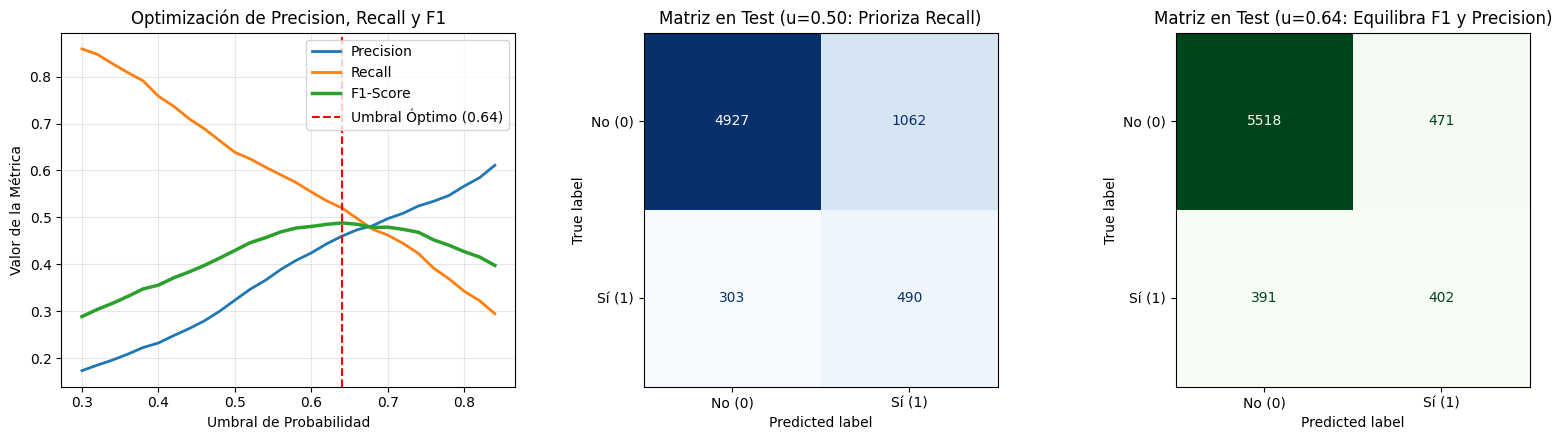

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Búsqueda del umbral óptimo en Validación para maximizar F1-Score
probs_val = modelo_optimizado.predict(X_val, verbose=0).ravel()
umbrales = np.arange(0.30, 0.85, 0.02)
precision_vals = [precision_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]
recall_vals = [recall_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]
f1_vals = [f1_score(y_val, (probs_val >= u).astype(int), zero_division=0) for u in umbrales]

mejor_idx = np.argmax(f1_vals)
mejor_umbral = umbrales[mejor_idx]

# 2. Evaluación Definitiva en el Conjunto de Prueba (X_test)
probs_test_base = modelo_base.predict(X_test, verbose=0).ravel()
probs_test_opt = modelo_optimizado.predict(X_test, verbose=0).ravel()

preds_test_base = (probs_test_base >= 0.50).astype(int)
preds_test_opt_05 = (probs_test_opt >= 0.50).astype(int)
preds_test_opt_umbral = (probs_test_opt >= mejor_umbral).astype(int)

resumen_final_test = pd.DataFrame({
    "1. MLP Base (ReLU, Batch=64, u=0.50)": [
        round(accuracy_score(y_test, preds_test_base), 4),
        round(precision_score(y_test, preds_test_base), 4),
        round(recall_score(y_test, preds_test_base), 4),
        round(f1_score(y_test, preds_test_base), 4)
    ],
    "2. MLP Optimizado (LeakyReLU + Reg, u=0.50) [Alto Recall]": [
        round(accuracy_score(y_test, preds_test_opt_05), 4),
        round(precision_score(y_test, preds_test_opt_05), 4),
        round(recall_score(y_test, preds_test_opt_05), 4),
        round(f1_score(y_test, preds_test_opt_05), 4)
    ],
    f"3. MLP Optimizado + Umbral Ajustado (u={mejor_umbral:.2f}) [Máximo F1]": [
        round(accuracy_score(y_test, preds_test_opt_umbral), 4),
        round(precision_score(y_test, preds_test_opt_umbral), 4),
        round(recall_score(y_test, preds_test_opt_umbral), 4),
        round(f1_score(y_test, preds_test_opt_umbral), 4)
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-Score"]).T

print("=== CUADRO RESUMEN FINAL DE CONFIGURACIONES (CONJUNTO DE PRUEBA - TEST) ===")
display(resumen_final_test)

# 3. Gráficos: Curva de Umbral (Precision-Recall-F1) y Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Gráfico 1: Trade-off Precision vs Recall según umbral
axes[0].plot(umbrales, precision_vals, label="Precision", color="tab:blue", linewidth=2)
axes[0].plot(umbrales, recall_vals, label="Recall", color="tab:orange", linewidth=2)
axes[0].plot(umbrales, f1_vals, label="F1-Score", color="tab:green", linewidth=2.5)
axes[0].axvline(mejor_umbral, color="red", linestyle="--", label=f"Umbral Óptimo ({mejor_umbral:.2f})")
axes[0].set_title("Optimización de Precision, Recall y F1")
axes[0].set_xlabel("Umbral de Probabilidad")
axes[0].set_ylabel("Valor de la Métrica")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Gráfico 2: Matriz de Confusión (Modo Alto Recall, u=0.50)
cm_05 = confusion_matrix(y_test, preds_test_opt_05)
ConfusionMatrixDisplay(cm_05, display_labels=["No (0)", "Sí (1)"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Matriz en Test (u=0.50: Prioriza Recall)")

# Gráfico 3: Matriz de Confusión (Modo Máximo F1, u=mejor_umbral)
cm_opt = confusion_matrix(y_test, preds_test_opt_umbral)
ConfusionMatrixDisplay(cm_opt, display_labels=["No (0)", "Sí (1)"]).plot(ax=axes[2], cmap="Greens", colorbar=False)
axes[2].set_title(f"Matriz en Test (u={mejor_umbral:.2f}: Equilibra F1 y Precision)")

plt.tight_layout()
plt.show()

## 6. Conclusiones y Reflexiones Finales

1. **Preprocesamiento y prevención de fuga de información:** Se excluyó `duration` porque solo se conoce al terminar la llamada y no estaría disponible al priorizar clientes antes del contacto. Se creó `contactado_antes` para representar el significado especial de `pdays = -1`, se codificaron las variables categóricas con One-Hot Encoding y se ajustó el escalador únicamente con el conjunto de entrenamiento.

2. **Hiperparámetros, funciones de activación y pérdida:** Los resultados dependen de la métrica utilizada. En la comparación de tasa de aprendizaje, `learning_rate = 0.01` obtuvo el mayor F1-Score (`0.4238`), mientras que `0.001` obtuvo la menor pérdida final de validación (`0.5159`). En la comparación de tamaño de lote, `batch_size = 256` obtuvo `F1-Score = 0.4428` y `Val Loss Final = 0.4745`. En la comparación de activación y pérdida, ReLU + Binary Crossentropy obtuvo el mayor F1-Score de validación (`0.4551`); LeakyReLU + Binary Crossentropy obtuvo `0.4402`. Por lo tanto, esta ejecución no demuestra que LeakyReLU haya sido la mejor combinación.

3. **Efecto observado de la regularización:** En validación, el modelo sin regularización obtuvo `Accuracy = 0.8055`, `Precision = 0.3242`, `Recall = 0.6096` y `F1-Score = 0.4233`. El modelo con Batch Normalization, Dropout y L2 obtuvo `Accuracy = 0.7861`, `Precision = 0.3053`, `Recall = 0.6486` y `F1-Score = 0.4152`. En esta ejecución, el recall aumentó, pero accuracy, precision y F1-Score disminuyeron. Como se aplicaron tres técnicas simultáneamente y la pérdida de entrenamiento usa `class_weight`, estos datos no bastan para afirmar que la regularización mejoró el desempeño general ni que eliminó el sobreajuste.

4. **Umbral de decisión y contexto del problema:** En test, el MLP con umbral `0.50` obtuvo `Precision = 0.3047`, `Recall = 0.6343` y `F1-Score = 0.4116`. Al usar el umbral `0.66`, elegido a partir de validación, obtuvo `Precision = 0.4537`, `Recall = 0.4943` y `F1-Score = 0.4731`. La precision y el F1-Score aumentaron, pero el recall disminuyó: se reducen los falsos positivos a costa de dejar sin identificar a más clientes que sí contratarían el depósito. El accuracy de `0.8713` (87.13 %) es inferior al baseline que siempre predice `no` (aproximadamente 88.31 % en este conjunto de prueba), por lo que no debemos afirmar que el modelo supera ese baseline en accuracy.

5. **Trabajo pendiente antes de cerrar la evaluación:** Todavía se deben incorporar experimentos controlados con distintos números de épocas y arquitecturas con diferente número de capas ocultas. También debemos revisar el efecto de la regularización con comparaciones justas, ejecutar el notebook completo de principio a fin y actualizar las conclusiones si los nuevos resultados cambian. Las afirmaciones finales deben corresponder siempre con las salidas de la última ejecución.